=== Scheduling Results (SJF) ===
Completed: 4   |   Total time: 15   |   Throughput: 0.267 processes/unit
Average waiting time: 2.75   |   Average turnaround time: 6.50



,pid,start,finish,waiting,turnaround
0,P4,0,1,0,1
1,P2,1,3,1,3
2,P3,3,7,3,7
3,P1,7,15,7,15


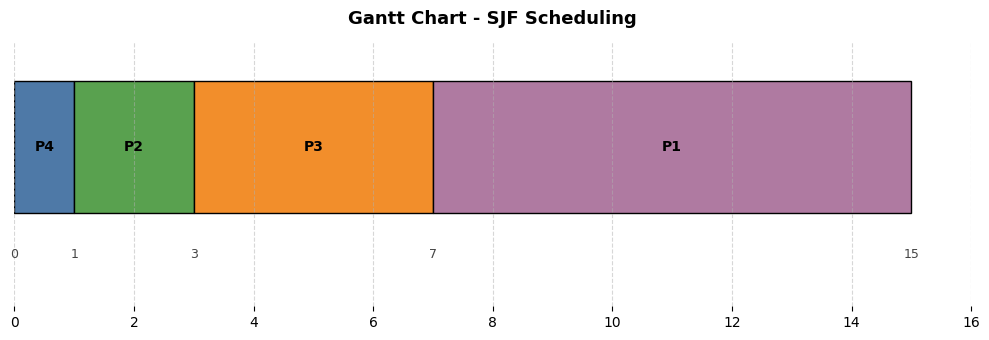

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def schedule(processes, algorithm):
    # Keep the original input position to resolve ties consistently.
    pending = [
        {**process, "input_order": index}
        for index, process in enumerate(processes)
    ]

    current_time = 0
    completed = []
    timeline = []

    while pending:
        ready = [
            process for process in pending
            if process["arrival"] <= current_time
        ]

        # If no process has arrived, move the clock to the next arrival.
        if not ready:
            next_arrival = min(
                process["arrival"] for process in pending
            )
            timeline.append({
                "pid": "IDLE",
                "start": current_time,
                "finish": next_arrival,
            })
            current_time = next_arrival

            ready = [
                process for process in pending
                if process["arrival"] <= current_time
            ]

        if algorithm == "SJF":
            chosen = min(
                ready,
                key=lambda p: (
                    p["burst"], p["arrival"], p["input_order"]
                ),
            )
        elif algorithm == "LJF":
            # Longest burst first; ties go to earlier arrival/input order.
            chosen = min(
                ready,
                key=lambda p: (
                    -p["burst"], p["arrival"], p["input_order"]
                ),
            )
        elif algorithm == "FCFS":
            chosen = min(
                ready,
                key=lambda p: (
                    p["arrival"], p["input_order"]
                ),
            )
        else:
            raise ValueError("Unsupported scheduling algorithm.")

        start = current_time
        finish = start + chosen["burst"]
        waiting = start - chosen["arrival"]
        turnaround = finish - chosen["arrival"]

        timeline.append({
            "pid": chosen["pid"],
            "start": start,
            "finish": finish,
        })

        completed.append({
            "pid": chosen["pid"],
            "start": start,
            "finish": finish,
            "waiting": waiting,
            "turnaround": turnaround,
        })

        current_time = finish
        pending.remove(chosen)

    return timeline, completed, current_time

def run_scheduling_simulation(processes, algorithm):
    timeline, completed, total_time = schedule(processes, algorithm)

    # Display overall metrics
    count = len(completed)
    total_waiting = sum(p["waiting"] for p in completed)
    total_turnaround = sum(p["turnaround"] for p in completed)
    average_waiting = total_waiting / count
    average_turnaround = total_turnaround / count
    throughput = count / total_time if total_time > 0 else 0

    print(f"=== Scheduling Results ({algorithm}) ===")
    print(f"Completed: {count}   |   Total time: {total_time}   |   Throughput: {throughput:.3f} processes/unit")
    print(f"Average waiting time: {average_waiting:.2f}   |   Average turnaround time: {average_turnaround:.2f}\n")

    # Display detailed tabular results
    df = pd.DataFrame(completed)
    display(df[["pid", "start", "finish", "waiting", "turnaround"]])

    # Plot Gantt Chart
    fig, ax = plt.subplots(figsize=(10, 3.5))
    colors = ["#4e79a7", "#59a14f", "#f28e2b", "#af7aa1", "#e15759", "#76b7b2"]

    for index, block in enumerate(timeline):
        color = "#dddddd" if block["pid"] == "IDLE" else colors[index % len(colors)]
        width = block["finish"] - block["start"]
        ax.barh(0, width, left=block["start"], color=color, edgecolor="black", height=0.5)

        # Draw the PID label inside the block
        ax.text(block["start"] + width/2, 0, block["pid"], ha='center', va='center', color='black', weight='bold')
        # Draw boundary time markers on the timeline axis
        ax.text(block["start"], -0.38, str(block["start"]), ha='center', va='top', fontsize=9, color="#444444")

    ax.text(total_time, -0.38, str(total_time), ha='center', va='top', fontsize=9, color="#444444")
    ax.set_yticks([])
    ax.set_ylim(-0.6, 0.4)
    ax.set_xlim(0, total_time + 1)
    ax.set_title(f"Gantt Chart - {algorithm} Scheduling", fontsize=13, weight='bold', pad=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.xaxis.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

# Sample input processes
sample_processes = [
    {"pid": "P1", "arrival": 0, "burst": 8},
    {"pid": "P2", "arrival": 0, "burst": 2},
    {"pid": "P3", "arrival": 0, "burst": 4},
    {"pid": "P4", "arrival": 0, "burst": 1},
]

# Run simulation
run_scheduling_simulation(sample_processes, "SJF")

=== SIMULATING SJF ===
=== Scheduling Results (SJF) ===
Completed: 4   |   Total time: 15   |   Throughput: 0.267 processes/unit
Average waiting time: 2.75   |   Average turnaround time: 6.50



,pid,start,finish,waiting,turnaround
0,P4,0,1,0,1
1,P2,1,3,1,3
2,P3,3,7,3,7
3,P1,7,15,7,15


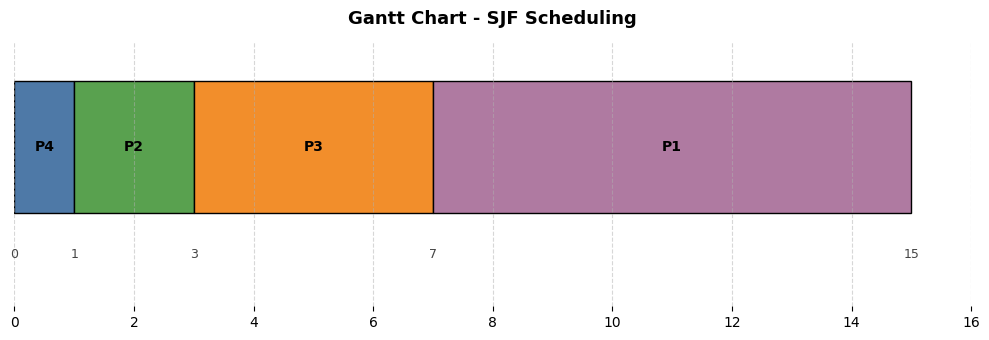



=== SIMULATING LJF ===
=== Scheduling Results (LJF) ===
Completed: 4   |   Total time: 15   |   Throughput: 0.267 processes/unit
Average waiting time: 8.50   |   Average turnaround time: 12.25



,pid,start,finish,waiting,turnaround
0,P1,0,8,0,8
1,P3,8,12,8,12
2,P2,12,14,12,14
3,P4,14,15,14,15


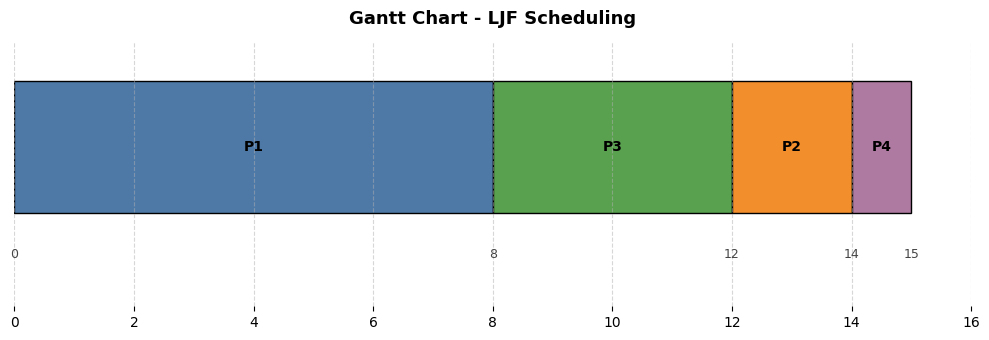

In [ ]:
# Compare performance metrics between SJF and LJF
print("=== SIMULATING SJF ===")
run_scheduling_simulation(sample_processes, "SJF")

print("\n" + "="*40 + "\n")

print("=== SIMULATING LJF ===")
run_scheduling_simulation(sample_processes, "LJF")

=== SIMULATING FCFS ===
=== Scheduling Results (FCFS) ===
Completed: 4   |   Total time: 15   |   Throughput: 0.267 processes/unit
Average waiting time: 8.00   |   Average turnaround time: 11.75



,pid,start,finish,waiting,turnaround
0,P1,0,8,0,8
1,P2,8,10,8,10
2,P3,10,14,10,14
3,P4,14,15,14,15


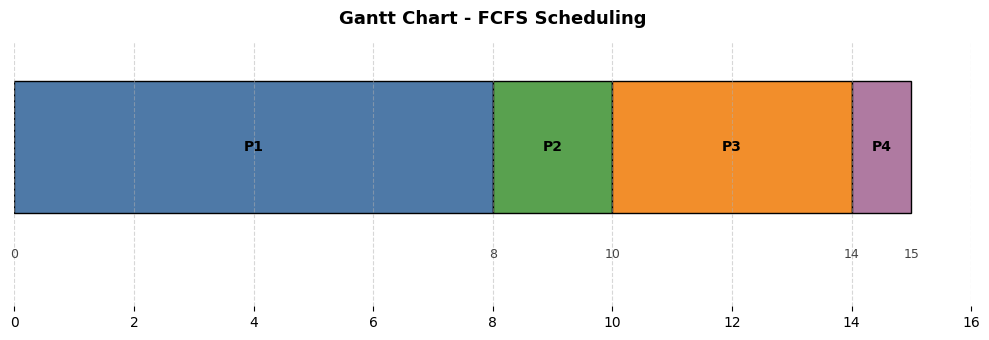

In [ ]:
print("=== SIMULATING FCFS ===")
run_scheduling_simulation(sample_processes, "FCFS")